# Tutorial 01: Clasificación de Arritmias ECG y Post-Training Quantization (PTQ)
### TinyML para Raspberry Pi Pico 2 / Pico 2 W (RP2350 - Cortex-M33) con TensorFlow y Arduino

En este tutorial aprenderás:
1. **Generación de bioseñales sintéticas** usando `neurokit2` (Ritmo Sinusal Normal, Taquicardia y Bradicardia/Ectópico).
2. **Diseño de una arquitectura 1D-CNN ultra-compacta** basada en convoluciones separables en profundidad (Depthwise-Separable Convolutions).
3. **Fundamentos matemáticos de la Cuantización Post-Entrenamiento (PTQ)** a enteros de 8 bits (INT8):
   $$q = \text{clip}\left(\text{round}\left(\frac{x}{S}\right) + Z, -128, 127\right)$$
4. **Calibración con Representative Dataset** para mapear los rangos dinámicos reales de activación.
5. **Exportación directa a un arreglo en C (`model_data.h`)** y muestras de prueba (`test_samples.h`) para inferencia en tiempo real en la Raspberry Pi Pico 2.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Añadir directorio raíz del proyecto
PROJECT_ROOT = Path("../../").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.signal_generator import generate_ecg_dataset
from utils.exporter import tflite_to_c_header, save_test_samples_header
from utils.tflite_eval import evaluate_tflite_model

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.16.2
GPU disponible: []


## 1. Generación de Señales Sintéticas de ECG con NeuroKit2
Generamos ventanas de 187 muestras a 250 Hz (estilo MIT-BIH Arrhythmia Database). Cada latido incluye variabilidad cardíaca y ruido fisiológico realista.

In [2]:
SAMPLE_LEN = 187
SAMPLING_RATE = 250
CLASS_NAMES = ["Normal", "Tachycardia", "Bradycardia"]

Dimensiones de X_train: (900, 187, 1) | X_test: (300, 187, 1)


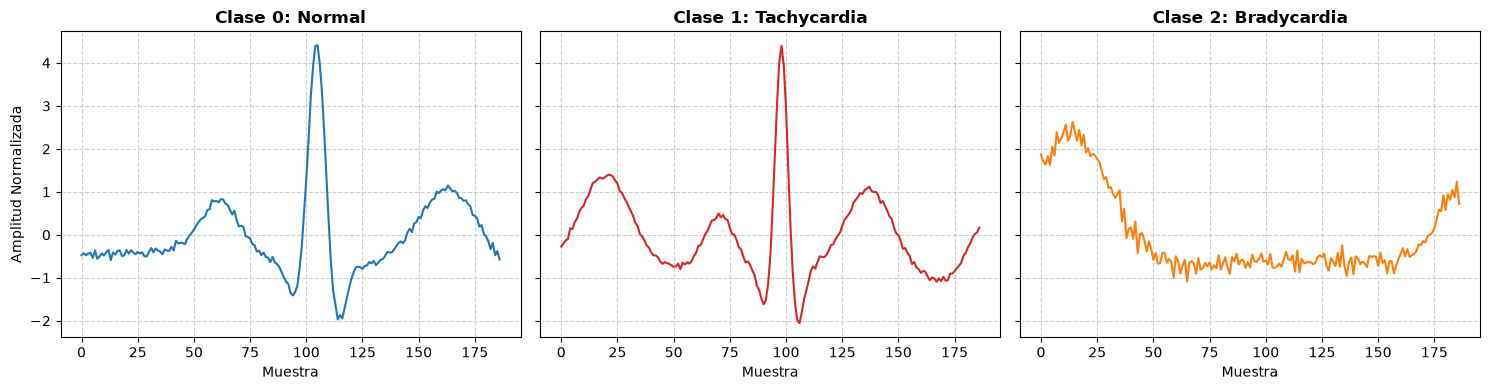

In [ ]:

X, y = generate_ecg_dataset(num_samples_per_class=400, sample_len=SAMPLE_LEN, sampling_rate=SAMPLING_RATE)
X = np.expand_dims(X, axis=-1) # Forma (N, 187, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"Dimensiones de X_train: {X_train.shape} | X_test: {X_test.shape}")

# Visualización de latidos sintéticos representativos
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for c_idx, c_name in enumerate(CLASS_NAMES):
    idx = np.where(y_train == c_idx)[0][0]
    axes[c_idx].plot(X_train[idx, :, 0], color='tab:blue' if c_idx==0 else ('tab:red' if c_idx==1 else 'tab:orange'))
    axes[c_idx].set_title(f"Clase {c_idx}: {c_name}", fontsize=12, fontweight='bold')
    axes[c_idx].set_xlabel("Muestra")
    axes[c_idx].grid(True, linestyle="--", alpha=0.6)
axes[0].set_ylabel("Amplitud Normalizada")
plt.tight_layout()
plt.show()

### optional saving the data

In [ ]:
# Save all arrays into a single compressed file
#np.savez_compressed(
#    "ecg_dataset.npz",
#    X_train=X_train,
#    X_test=X_test,
#    y_train=y_train,
#    y_test=y_test,
#)
#print("Dataset successfully saved as ecg_dataset.npz")

NameError: name 'X_train' is not defined

In [3]:
# Load the archive
data = np.load("ecg_dataset.npz")

# Access individual arrays
X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]

print("Dataset successfully loaded!")
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

Dataset successfully loaded!
X_train shape: (900, 187, 1) | X_test shape: (300, 187, 1)


## 2. Construcción del Modelo 1D-CNN (Optimizado para Microcontrolador RP2350)
Para operar en microcontroladores con presupuestos estrictos de memoria SRAM y Flash, utilizamos **SeparableConv1D** (convolución separable espacial/canal), lo cual reduce los parámetros en más del 70% comparado con convoluciones 1D tradicionales.

In [4]:
def build_tiny_ecg_model(input_shape=(SAMPLE_LEN, 1), num_classes=3):
    inputs = tf.keras.Input(shape=input_shape, name="ecg_input")
    
    # Bloque 1
    x = tf.keras.layers.Conv1D(filters=8, kernel_size=7, strides=2, padding="same", use_bias=False)(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    
    # Bloque 2: Depthwise Separable
    x = tf.keras.layers.SeparableConv1D(filters=16, kernel_size=5, strides=2, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    
    # Bloque 3: Depthwise Separable
    x = tf.keras.layers.SeparableConv1D(filters=32, kernel_size=3, strides=2, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    
    # Global Pooling + Clasificador
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="probabilities")(x)
    
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="tiny_ecg_cnn")

model = build_tiny_ecg_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "tiny_ecg_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ecg_input (InputLayer)          │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 94, 8)          │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 94, 8)          │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 94, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv1d                │ (None, 47, 16)         │           168 │
│ (SeparableConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 47, 16)         │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 47, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv1d_1              │ (None, 24, 32)         │           560 │
│ (SeparableConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,107 (4.32 KB)

 Trainable params: 995 (3.89 KB)

 Non-trainable params: 112 (448.00 B)

## 3. Entrenamiento del Modelo Base

In [5]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=32,
    verbose=1
)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nExactitud en Test (Float32): {test_acc * 100:.2f}%")

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.5400 - loss: 0.9257 - val_accuracy: 0.3333 - val_loss: 1.0967
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7622 - loss: 0.6324 - val_accuracy: 0.3567 - val_loss: 1.1071
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8567 - loss: 0.4815 - val_accuracy: 0.3367 - val_loss: 1.1328
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8811 - loss: 0.3932 - val_accuracy: 0.4733 - val_loss: 1.1134
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9044 - loss: 0.3421 - val_accuracy: 0.3367 - val_loss: 1.0139
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9122 - loss: 0.3081 - val_accuracy: 0.3533 - val_loss: 0.8588
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9256 - loss: 0.2633 - val_accuracy: 0.6133 - val_loss: 0.7299
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9411 - loss: 0.2228 - val_accuracy: 0.7033 - v

## 4. Cuantización Post-Entrenamiento (PTQ) a Full INT8
Convertimos pesos y activaciones a enteros de 8 bits con signo (`int8`, rango $[-128, 127]$). La Raspberry Pi Pico 2 posee extensiones DSP en el núcleo ARM Cortex-M33 capaces de ejecutar instrucciones SIMD que procesan hasta 4 multiplicaciones y acumulaciones de 8 bits por ciclo de reloj (`SMLAD`).

In [6]:
import gc
import tensorflow as tf

# Force garbage collection before conversion to clear memory blocks
gc.collect()


def representative_data_gen():
  for i in range(min(200, len(X_train))):
    # Ensure proper float32 casting and explicit dimension wrapping
    yield [X_train[i : i + 1].astype("float32")]


converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_data_gen

# Enforce full integer constraints for inputs and outputs
converter_int8.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8

# Convert safely
tflite_int8 = converter_int8.convert()
print("INT8 conversion successful!")

size_float_kb = len(tflite_float) / 1024.0
size_int8_kb = len(tflite_int8) / 1024.0
print(f"Tamaño Modelo Float32: {size_float_kb:.2f} KB")
print(f"Tamaño Modelo INT8:    {size_int8_kb:.2f} KB")
print(f"Factor de Compresión:  {size_float_kb / size_int8_kb:.2f}x")

INFO:tensorflow:Assets written to: C:\Users\47470482\AppData\Local\Temp\tmpxy1f7p53\assets


INFO:tensorflow:Assets written to: C:\Users\47470482\AppData\Local\Temp\tmpxy1f7p53\assets


: 

In [9]:
# 1. Conversión Float32
converter_float = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float = converter_float.convert()

# 2. Conversión Full INT8 con Representative Dataset
def representative_data_gen():
    for i in range(min(200, len(X_train))):
        yield [X_train[i:i+1].astype(np.float32)]

converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_data_gen
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8
tflite_int8 = converter_int8.convert()

size_float_kb = len(tflite_float) / 1024.0
size_int8_kb = len(tflite_int8) / 1024.0
print(f"Tamaño Modelo Float32: {size_float_kb:.2f} KB")
print(f"Tamaño Modelo INT8:    {size_int8_kb:.2f} KB")
print(f"Factor de Compresión:  {size_float_kb / size_int8_kb:.2f}x")

INFO:tensorflow:Assets written to: C:\Users\47470482\AppData\Local\Temp\tmp9xtpzdi3\assets


INFO:tensorflow:Assets written to: C:\Users\47470482\AppData\Local\Temp\tmp9xtpzdi3\assets


: 

## 5. Evaluación de Exactitud Cuantizada y Exportación a C (`model_data.h`)

In [ ]:
res_int8 = evaluate_tflite_model(tflite_int8, X_test, y_test)
print(f"Exactitud Modelo Cuantizado INT8: {res_int8['accuracy'] * 100:.2f}%")
print(f"Escala de Entrada: {res_int8['input_scale']:.6f} | Zero-Point: {res_int8['input_zero_point']}")

# Guardar en el directorio de Arduino del Ejemplo 01
ARDUINO_DIR = Path("../arduino/ecg_inference_pico2")
ARDUINO_DIR.mkdir(parents=True, exist_ok=True)

tflite_to_c_header(tflite_int8, str(ARDUINO_DIR / "model_data.h"))
save_test_samples_header(X_test[:, :, 0], y_test, str(ARDUINO_DIR / "test_samples.h"), CLASS_NAMES, samples_per_class=3)
print("Archivos C listos para compilar en Arduino IDE!")